In [6]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.metrics import classification_report
from IPython.display import display


In [8]:
filepath = "/content/drive/MyDrive/dataset/adult_dataset.csv"
df = pd.read_csv(filepath)
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


## 2. First look and data inspection


In [9]:
print("Shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all").T)

Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,46400.0,NaN,NaN,NaN,38.679116,13.952954,17.0,28.0,37.0,48.0,255.0
workclass,45480,9,Private,32220,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,45485,15,Prof-specialty,5854,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
for col in df.columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(20))


age
age
NaN     2442
33.0    1289
36.0    1289
35.0    1276
23.0    1258
31.0    1245
37.0    1238
34.0    1237
28.0    1210
30.0    1207
38.0    1197
32.0    1196
41.0    1182
27.0    1159
29.0    1142
39.0    1136
24.0    1134
25.0    1132
22.0    1127
40.0    1123
Name: count, dtype: int64

workclass
workclass
Private             32220
Self-emp-not-inc     3649
NaN                  3362
Local-gov            2973
State-gov            1877
?                    1763
Self-emp-inc         1625
Federal-gov          1346
Without-pay            18
Never-worked            9
Name: count, dtype: int64

fnlwgt
fnlwgt
203488    21
120277    19
190290    19
126569    18
125892    18
126675    17
113364    17
99185     17
111567    16
186934    16
127651    15
120131    15
117963    15
123011    15
164190    14
136986    14
132879    14
148995    14
188246    14
194630    14
Name: count, dtype: int64

education
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters   

## 3. Basic text cleanup and target inspection

The Adult Income dataset commonly stores missing categorical values as `?`.

In [11]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df = df.replace("?", np.nan)

target_col = "income"
if target_col not in df.columns:
    raise ValueError(f"Expected target column '{target_col}' was not found. Check the dataset column names.")

df[target_col] = df[target_col].astype("string").str.strip().str.replace(r"\.$", "", regex=True)
display(df[target_col].value_counts(dropna=False))

,count
income,
<=50K,37155
>50K,11687


Trailing periods and surrounding spaces are standardised so that equivalent target labels are not treated as different classes. The target column is retained because it is the prediction label.

## 4. Visualisation

In [12]:
numeric_cols_initial = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols_initial = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Numerical columns:", numeric_cols_initial)
print("Categorical columns:", categorical_cols_initial)

Numerical columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']


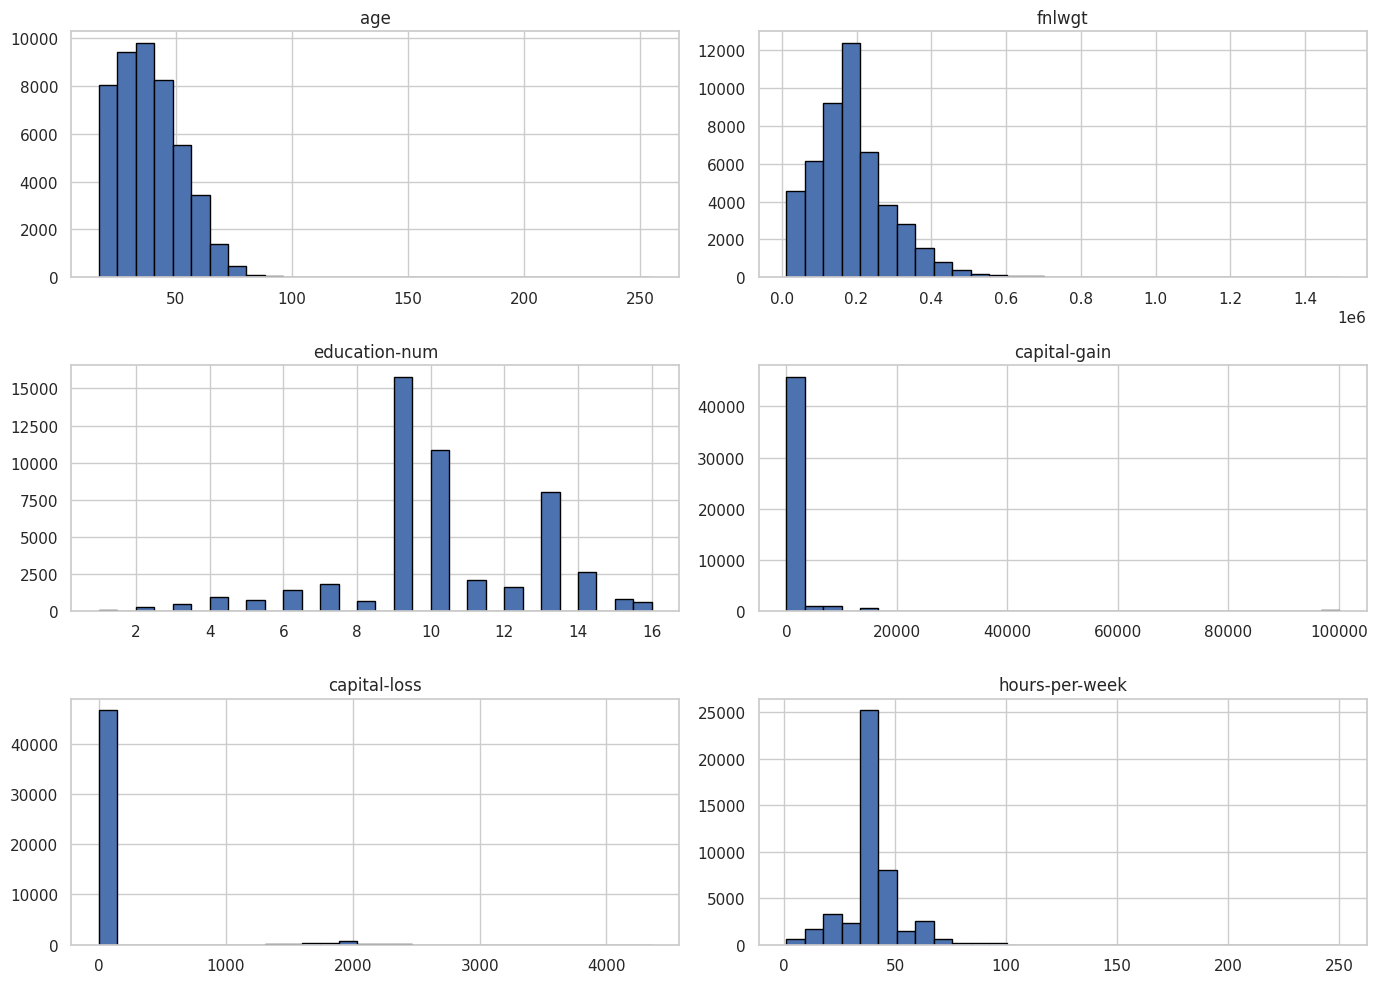

In [13]:
df[numeric_cols_initial].hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

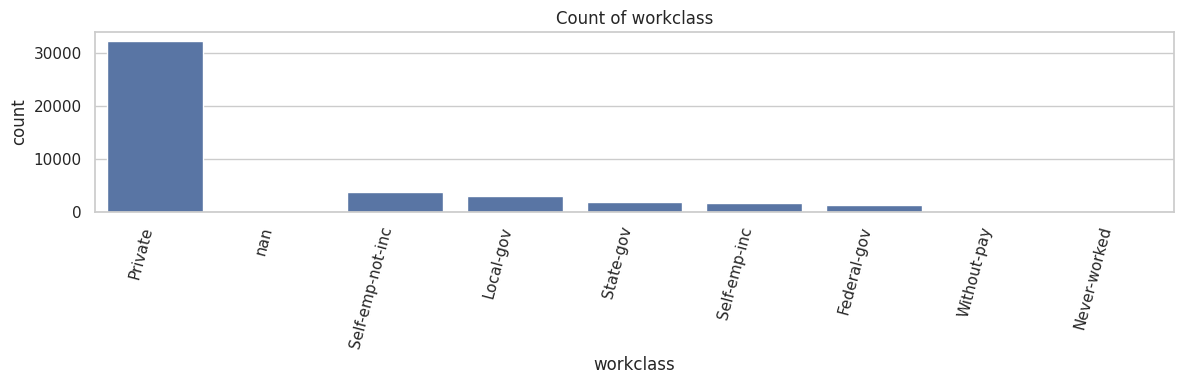

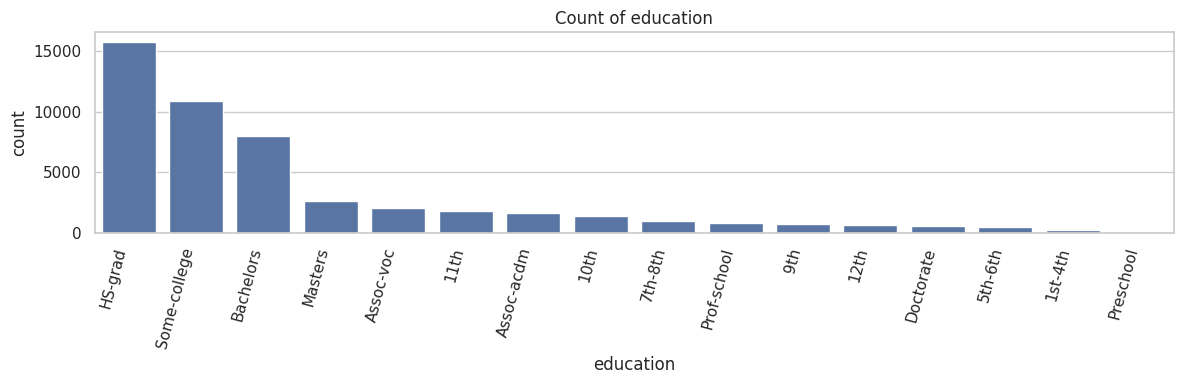

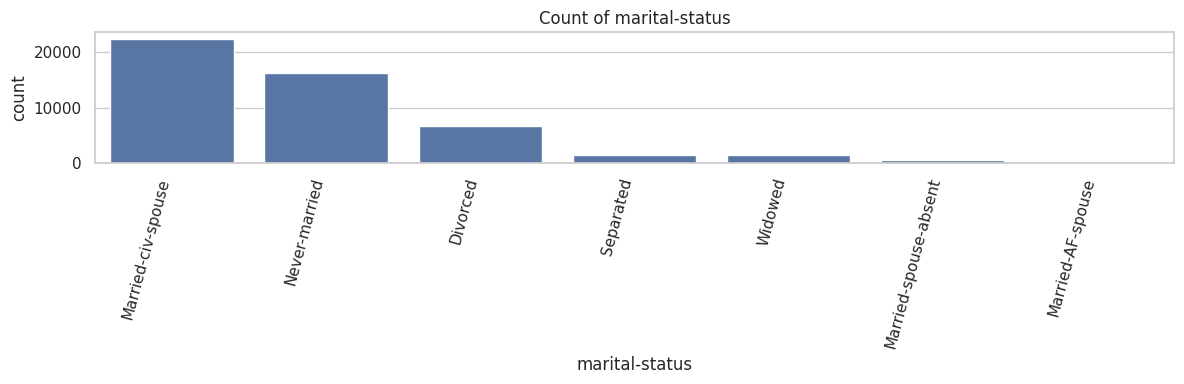

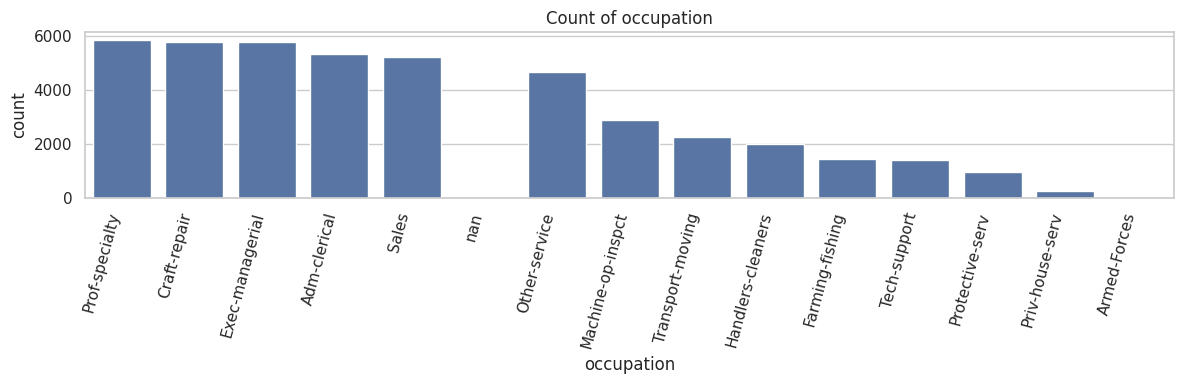

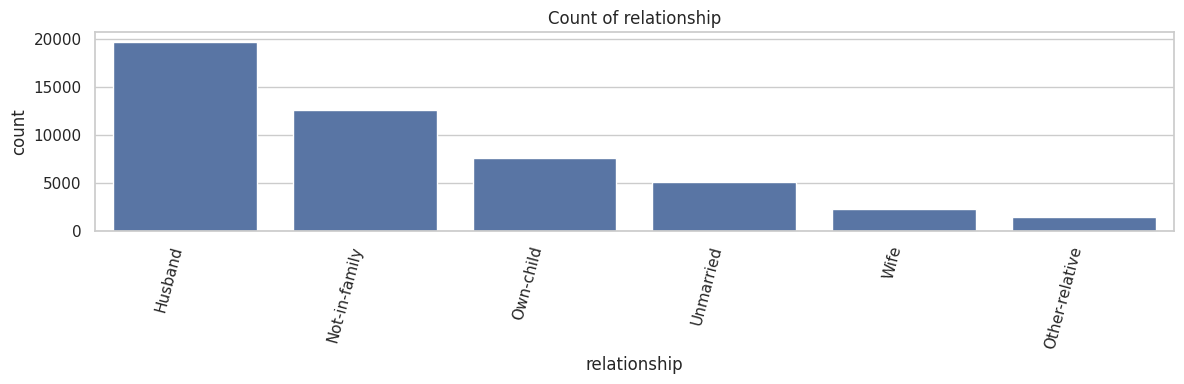

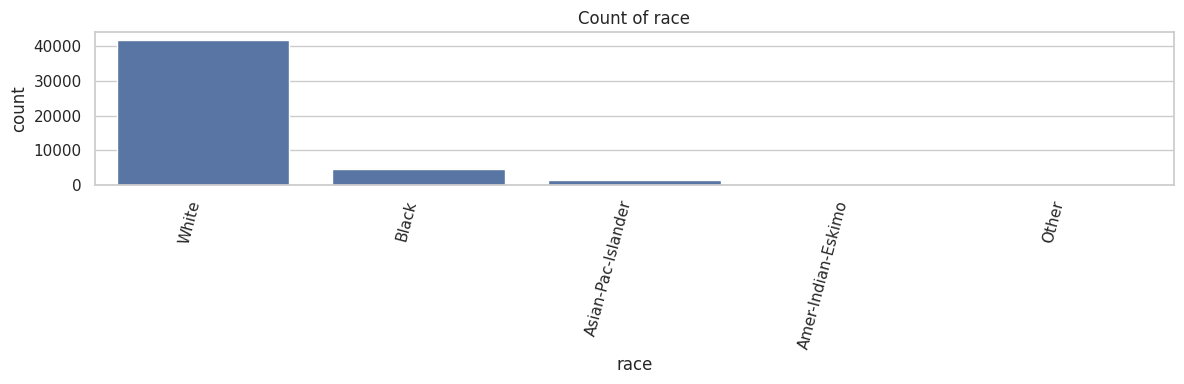

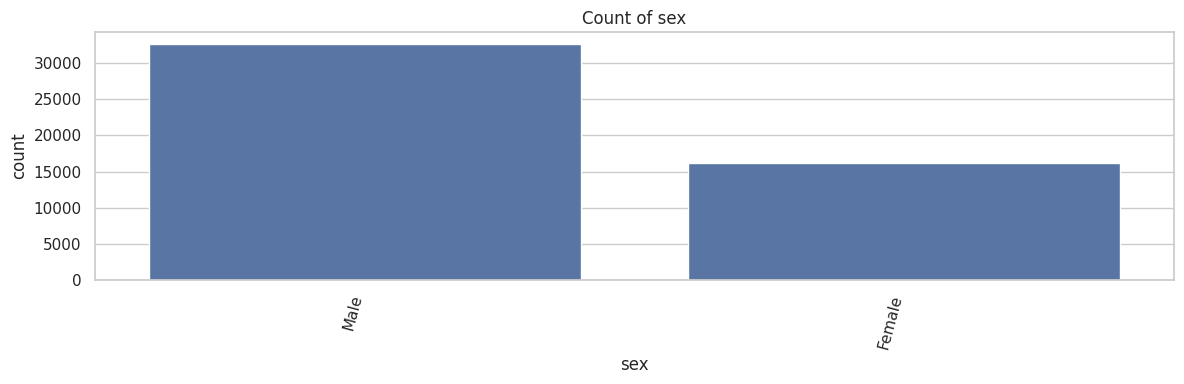

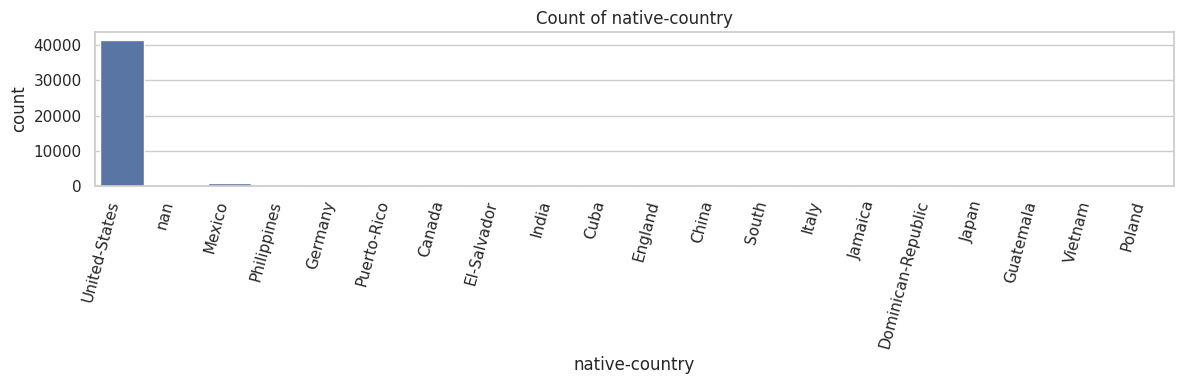

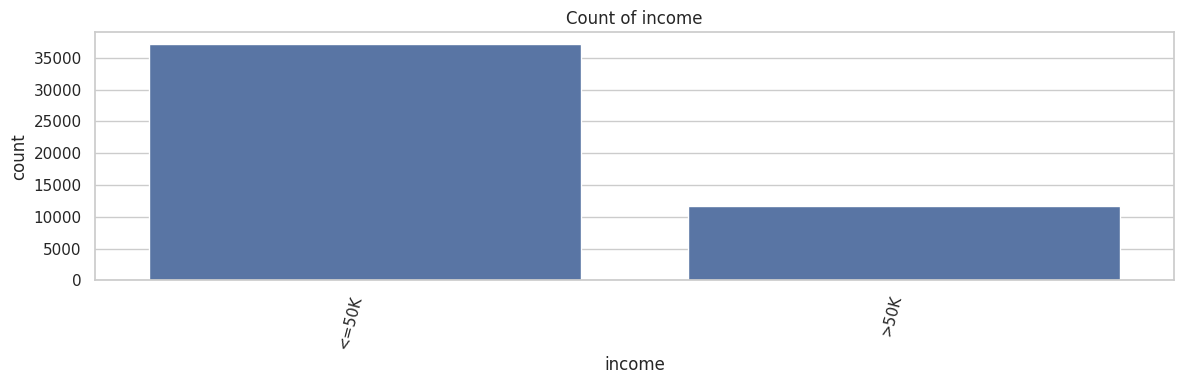

In [14]:
for col in categorical_cols_initial:
    plt.figure(figsize=(12, 4))
    order = df[col].value_counts(dropna=False).head(20).index
    sns.countplot(data=df, x=col, order=order)
    plt.xticks(rotation=75, ha="right")
    plt.title(f"Count of {col}")
    plt.tight_layout()
    plt.show()

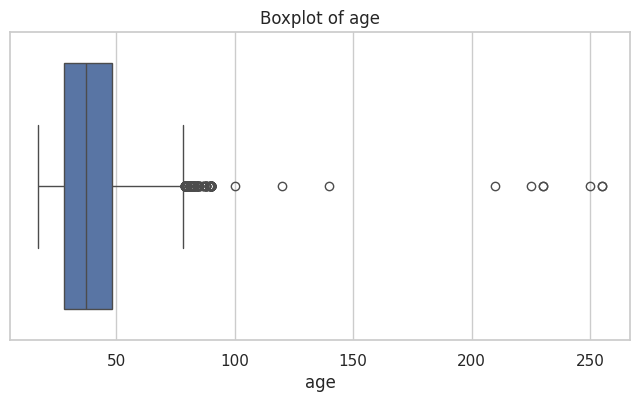

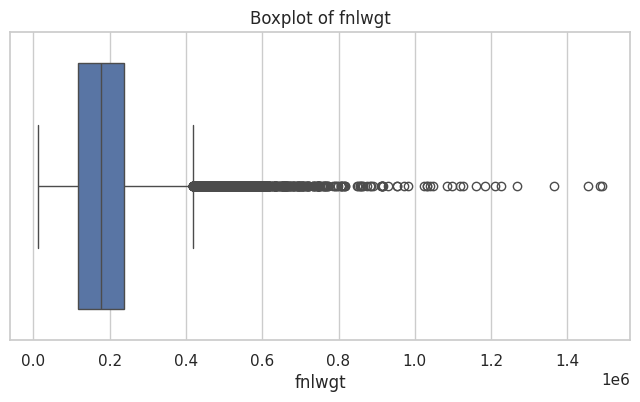

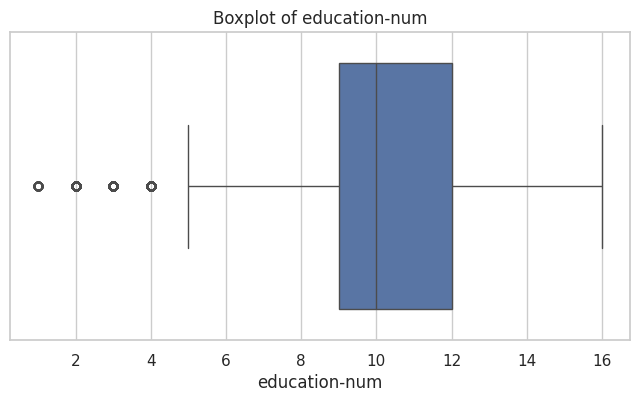

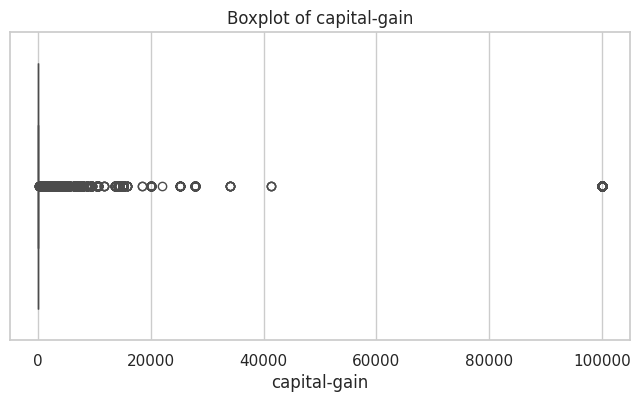

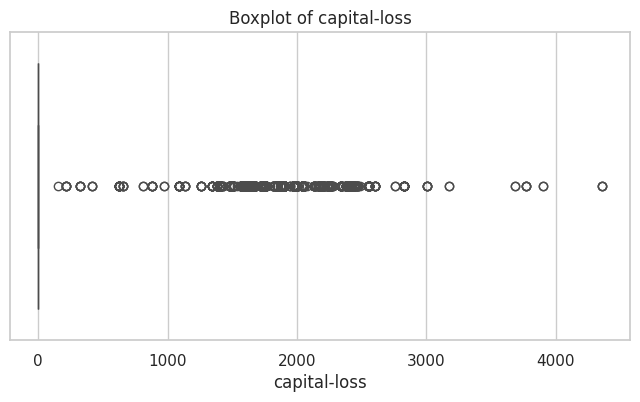

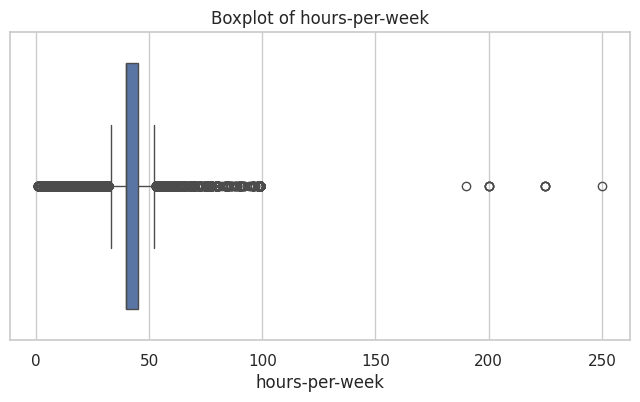

In [15]:
for col in numeric_cols_initial:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

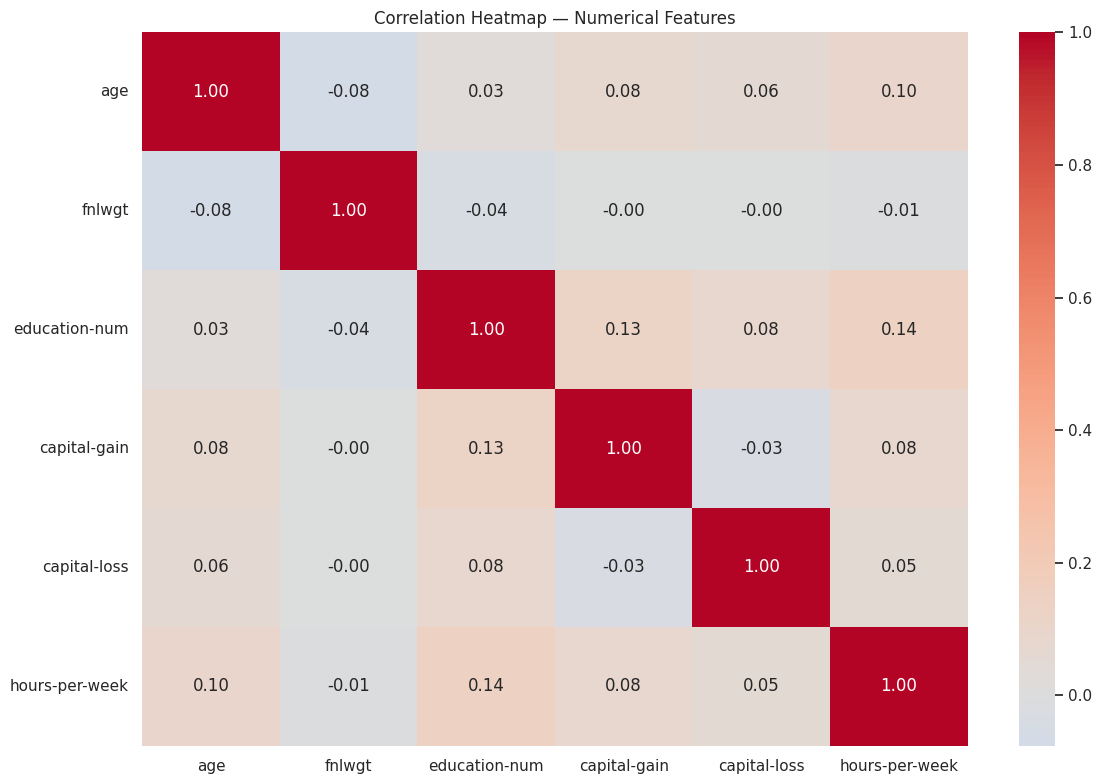

In [16]:
if len(numeric_cols_initial) > 1:
    plt.figure(figsize=(12, 8))
    sns.heatmap(df[numeric_cols_initial].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap — Numerical Features")
    plt.tight_layout()
    plt.show()

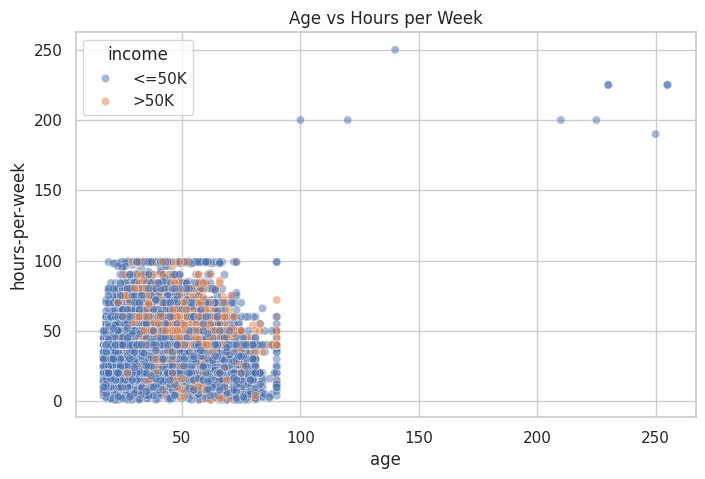

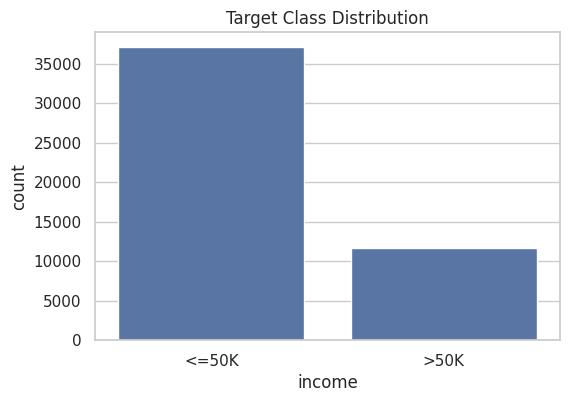

In [17]:
if "age" in df.columns and "hours-per-week" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x="age", y="hours-per-week", hue=target_col, alpha=0.5)
    plt.title("Age vs Hours per Week")
    plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target_col)
plt.title("Target Class Distribution")
plt.show()

### Visualisation observations
Skewed

## 5. Duplicate detection and handling


In [18]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)
display(df[df.duplicated(keep=False)].head(10))

Duplicate rows: 29


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
2195,39.0,Private,184659,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40.0,United-States,<=50K
2303,90.0,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35.0,United-States,<=50K
3118,19.0,Private,130431,5th-6th,3,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,36.0,Mexico,<=50K
3917,19.0,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14.0,United-States,<=50K
4325,25.0,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40.0,Mexico,<=50K
4767,21.0,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10.0,United-States,<=50K
5104,90.0,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35.0,United-States,<=50K
5579,27.0,Private,255582,HS-grad,9,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40.0,United-States,<=50K
5805,20.0,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10.0,United-States,<=50K
5842,25.0,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40.0,Guatemala,<=50K


Exact duplicate records are removed because they repeat the same observation.

In [19]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate handling:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after duplicate handling: (48813, 15)
Remaining duplicates: 0


## 6. Missing-value investigation


In [20]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
})
display(missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_percent", ascending=False))

,missing_count,missing_percent,dtype
workclass,5121,10.49,object
occupation,5111,10.47,object
native-country,3260,6.68,object
age,2442,5.00,float64
hours-per-week,2442,5.00,float64


In [21]:
for col in df.columns[df.isna().any()]:
    print(f"\nColumn: {col}")
    display(df[col].value_counts(dropna=False).head(20))


Column: age


,count
age,
NaN,2442
33.0,1289
36.0,1289
35.0,1275
23.0,1256
31.0,1245
34.0,1237
37.0,1237
28.0,1210



Column: workclass


,count
workclass,
Private,32196
NaN,5121
Self-emp-not-inc,3649
Local-gov,2973
State-gov,1877
Self-emp-inc,1624
Federal-gov,1346
Without-pay,18
Never-worked,9



Column: occupation


,count
occupation,
Prof-specialty,5850
Craft-repair,5787
Exec-managerial,5770
Adm-clerical,5328
Sales,5230
NaN,5111
Other-service,4654
Machine-op-inspct,2871
Transport-moving,2238



Column: hours-per-week


,count
hours-per-week,
40.0,21673
50.0,4014
45.0,2565
NaN,2442
60.0,2077
35.0,1840
20.0,1772
30.0,1618
55.0,997



Column: native-country


,count
native-country,
United-States,41600
NaN,3260
Mexico,902
Philippines,282
Germany,194
Puerto-Rico,175
Canada,170
El-Salvador,147
India,143


### Missing-value decisions

The imputers below are fitted only on the training split.

## 7. Outlier investigation



In [22]:
numeric_cols_for_outliers = df.select_dtypes(include=np.number).columns.tolist()
outlier_rows = []

for col in numeric_cols_for_outliers:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "column": col,
        "lower_limit": lower,
        "upper_limit": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percent": round(mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_count", ascending=False)
display(outlier_summary)

,column,lower_limit,upper_limit,outlier_count,outlier_percent
5,hours-per-week,32.5,52.5,12832,26.29
3,capital-gain,0.0,0.0,4035,8.27
4,capital-loss,0.0,0.0,2282,4.67
2,education-num,4.5,16.5,1790,3.67
1,fnlwgt,-62529.0,417679.0,1453,2.98
0,age,-2.0,78.0,210,0.43


In [23]:
for col in numeric_cols_for_outliers:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged_values = df.loc[(df[col] < lower) | (df[col] > upper), col]
    print(f"\n{col}")
    display(flagged_values.value_counts().head(20))


age


,count
age,
90.0,52
81.0,35
80.0,32
79.0,29
82.0,14
83.0,11
84.0,10
88.0,6
85.0,5



fnlwgt


,count
fnlwgt,
445382,7
481987,5
455995,5
443546,5
423222,5
473133,5
421837,5
609789,4
421633,4



education-num


,count
education-num,
4,955
3,507
2,246
1,82


... (2 outputs left out)


capital-loss


,count
capital-loss,
1902,304
1977,253
1887,233
2415,72
1485,71
1848,67
1590,62
1602,62
1876,59



hours-per-week


,count
hours-per-week,
60.0,2077
20.0,1772
30.0,1618
55.0,997
25.0,903
15.0,591
70.0,410
32.0,406
10.0,405


Remove or correct a value only when inspection shows it is impossible, corrupted, or a data-entry error.

## 8. Define features and target, then split the data



In [24]:
X = df.drop(columns=[target_col])
y = df[target_col].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (39050, 14)
X_test: (9763, 14)
y_train: (39050,)
y_test: (9763,)


 All learned preprocessing steps are fitted on `X_train` or `y_train` only, then applied to the test set with `transform()`.

## 9. Identify numerical and categorical columns


In [25]:
if "education" in X_train.columns and "education-num" in X_train.columns:
    X_train = X_train.drop(columns=["education-num"])
    X_test = X_test.drop(columns=["education-num"])

ordinal_col = "education" if "education" in X_train.columns else None
ordinal_cols = [ordinal_col] if ordinal_col else []

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
onehot_cols = [col for col in categorical_cols if col not in ordinal_cols]

print("Numerical:", numeric_cols)
print("Ordinal:", ordinal_cols)
print("One-hot:", onehot_cols)

Numerical: ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']
Ordinal: ['education']
One-hot: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


f both `education` and `education-num` are present, `education-num` is dropped because it encodes the same education ordering numerically. The ordinal `education` feature is retained.

## 10. Numerical missing-value imputation

Use the median for numerical features. Fit the imputer on training data and transform the test data.

In [26]:
num_imputer = SimpleImputer(strategy="median")

X_train_num = pd.DataFrame(
    num_imputer.fit_transform(X_train[numeric_cols]),
    columns=numeric_cols,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    num_imputer.transform(X_test[numeric_cols]),
    columns=numeric_cols,
    index=X_test.index
)

Median imputation is used because it is less sensitive to extreme values than the mean. The median is learned from the training set only.

## 11. Categorical missing-value imputation


In [27]:
if ordinal_cols:
    ordinal_imputer = SimpleImputer(strategy="most_frequent")
    X_train_ordinal_raw = pd.DataFrame(
        ordinal_imputer.fit_transform(X_train[ordinal_cols]),
        columns=ordinal_cols,
        index=X_train.index
    )
    X_test_ordinal_raw = pd.DataFrame(
        ordinal_imputer.transform(X_test[ordinal_cols]),
        columns=ordinal_cols,
        index=X_test.index
    )
else:
    X_train_ordinal_raw = pd.DataFrame(index=X_train.index)
    X_test_ordinal_raw = pd.DataFrame(index=X_test.index)

if onehot_cols:
    nominal_imputer = SimpleImputer(strategy="most_frequent")
    X_train_nominal_raw = pd.DataFrame(
        nominal_imputer.fit_transform(X_train[onehot_cols]),
        columns=onehot_cols,
        index=X_train.index
    )
    X_test_nominal_raw = pd.DataFrame(
        nominal_imputer.transform(X_test[onehot_cols]),
        columns=onehot_cols,
        index=X_test.index
    )
else:
    X_train_nominal_raw = pd.DataFrame(index=X_train.index)
    X_test_nominal_raw = pd.DataFrame(index=X_test.index)

The most frequent category is used because it preserves a valid category and does not create a new artificial category. The mode is learned from the training data only.

## 12. Ordinal encoding

Education levels have a meaningful order. The category order below follows the common Adult dataset education categories.

In [28]:
if ordinal_cols:
    education_order = [
        "Preschool",
        "1st-4th",
        "5th-6th",
        "7th-8th",
        "9th",
        "10th",
        "11th",
        "12th",
        "HS-grad",
        "Some-college",
        "Assoc-voc",
        "Assoc-acdm",
        "Bachelors",
        "Masters",
        "Prof-school",
        "Doctorate"
    ]

    print("Education values in training data:", sorted(X_train_ordinal_raw[ordinal_col].astype(str).unique()))
    ordinal_encoder = OrdinalEncoder(
        categories=[education_order],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )
    X_train_ordinal = pd.DataFrame(
        ordinal_encoder.fit_transform(X_train_ordinal_raw),
        columns=ordinal_cols,
        index=X_train.index
    )
    X_test_ordinal = pd.DataFrame(
        ordinal_encoder.transform(X_test_ordinal_raw),
        columns=ordinal_cols,
        index=X_test.index
    )
else:
    X_train_ordinal = pd.DataFrame(index=X_train.index)
    X_test_ordinal = pd.DataFrame(index=X_test.index)

Education values in training data: ['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th', '9th', 'Assoc-acdm', 'Assoc-voc', 'Bachelors', 'Doctorate', 'HS-grad', 'Masters', 'Preschool', 'Prof-school', 'Some-college']


 Education is ordinal-encoded because its categories have a natural educational progression. Unknown categories are assigned `-1` rather than causing the transformation to fail.

## 13. One-hot encoding

Use one-hot encoding for nominal categories because they do not have a natural ranking.

In [29]:
if onehot_cols:
    onehot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
    X_train_onehot_array = onehot_encoder.fit_transform(X_train_nominal_raw)
    X_test_onehot_array = onehot_encoder.transform(X_test_nominal_raw)

    onehot_feature_names = onehot_encoder.get_feature_names_out(onehot_cols)

    X_train_onehot = pd.DataFrame(
        X_train_onehot_array,
        columns=onehot_feature_names,
        index=X_train.index
    )
    X_test_onehot = pd.DataFrame(
        X_test_onehot_array,
        columns=onehot_feature_names,
        index=X_test.index
    )
else:
    X_train_onehot = pd.DataFrame(index=X_train.index)
    X_test_onehot = pd.DataFrame(index=X_test.index)

Nominal categorical features are one-hot encoded because their labels have no meaningful numerical order. The encoder is fitted on training data only, and unseen test categories are handled with `handle_unknown="ignore"`.

## 14. Combine encoded categorical and numerical DataFrames

In [30]:
X_train_encoded = pd.concat(
    [X_train_num, X_train_ordinal, X_train_onehot],
    axis=1
)

X_test_encoded = pd.concat(
    [X_test_num, X_test_ordinal, X_test_onehot],
    axis=1
)

X_train_encoded = X_train_encoded.astype(float)
X_test_encoded = X_test_encoded.astype(float)

print("Training encoded shape:", X_train_encoded.shape)
print("Testing encoded shape:", X_test_encoded.shape)
display(X_train_encoded.head())

Training encoded shape: (39050, 89)
Testing encoded shape: (9763, 89)


,age,fnlwgt,capital-gain,capital-loss,hours-per-week,education,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Divorced,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
33429,37.0,207668.0,0.0,0.0,40.0,12.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
39963,44.0,40024.0,0.0,0.0,40.0,8.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
47801,37.0,53232.0,0.0,0.0,55.0,14.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
46455,23.0,71996.0,0.0,0.0,52.0,12.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
30881,45.0,34127.0,0.0,0.0,50.0,12.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


## 15. Transformation for skewed numerical features

The Adult dataset often contains highly right-skewed `capital-gain` and `capital-loss`.

In [31]:
skewness_before = X_train_num.skew().sort_values(ascending=False)
display(skewness_before.to_frame("skewness_before"))

,skewness_before
capital-gain,12.139125
capital-loss,4.578328
fnlwgt,1.482296
age,1.014209
hours-per-week,0.740973


In [32]:
transform_cols = [
    col for col in ["capital-gain", "capital-loss"]
    if col in X_train_encoded.columns
    and (X_train_encoded[col] >= 0).all()
]

for col in transform_cols:
    X_train_encoded[col] = np.log1p(X_train_encoded[col])
    X_test_encoded[col] = np.log1p(X_test_encoded[col])

print("Log-transformed columns:", transform_cols)

Log-transformed columns: ['capital-gain', 'capital-loss']


`log1p` is used for non-negative, strongly right-skewed capital columns because it can reduce skew while retaining zero values.

## 16. Variance Threshold

Variance Threshold is fitted on the training features before scaling, as required.

In [33]:
variance_threshold = 0.01
variance_selector = VarianceThreshold(threshold=variance_threshold)

X_train_variance_array = variance_selector.fit_transform(X_train_encoded)
X_test_variance_array = variance_selector.transform(X_test_encoded)

variance_kept_columns = X_train_encoded.columns[variance_selector.get_support()].tolist()
variance_removed_columns = X_train_encoded.columns[~variance_selector.get_support()].tolist()

X_train_variance = pd.DataFrame(
    X_train_variance_array,
    columns=variance_kept_columns,
    index=X_train_encoded.index
)

X_test_variance = pd.DataFrame(
    X_test_variance_array,
    columns=variance_kept_columns,
    index=X_test_encoded.index
)

print("Kept features:", variance_kept_columns)
print("Removed features:", variance_removed_columns)

Kept features: ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week', 'education', 'workclass_Federal-gov', 'workclass_Local-gov', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'marital-status_Divorced', 'marital-status_Married-civ-spouse', 'marital-status_Married-spouse-absent', 'marital-status_Never-married', 'marital-status_Separated', 'marital-status_Widowed', 'occupation_Adm-clerical', 'occupation_Craft-repair', 'occupation_Exec-managerial', 'occupation_Farming-fishing', 'occupation_Handlers-cleaners', 'occupation_Machine-op-inspct', 'occupation_Other-service', 'occupation_Prof-specialty', 'occupation_Protective-serv', 'occupation_Sales', 'occupation_Tech-support', 'occupation_Transport-moving', 'relationship_Husband', 'relationship_Not-in-family', 'relationship_Other-relative', 'relationship_Own-child', 'relationship_Unmarried', 'relationship_Wife', 'race_Asian-Pac-Islander', 'race_Black', 'race_White', 'sex_Femal

Features below the selected variance threshold are removed only after checking their names and meaning.

## 17. Identify binary columns and continuous numerical columns

Do not scale binary 0/1 features or the target. Scale only continuous numerical features that remain after variance selection.

In [34]:
binary_cols = [
    col for col in X_train_variance.columns
    if set(X_train_variance[col].dropna().unique()).issubset({0.0, 1.0})
]

continuous_cols = [col for col in X_train_variance.columns if col not in binary_cols]

print("Binary columns not to be scaled:", binary_cols)
print("Continuous columns to scale:", continuous_cols)

Binary columns not to be scaled: ['workclass_Federal-gov', 'workclass_Local-gov', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'marital-status_Divorced', 'marital-status_Married-civ-spouse', 'marital-status_Married-spouse-absent', 'marital-status_Never-married', 'marital-status_Separated', 'marital-status_Widowed', 'occupation_Adm-clerical', 'occupation_Craft-repair', 'occupation_Exec-managerial', 'occupation_Farming-fishing', 'occupation_Handlers-cleaners', 'occupation_Machine-op-inspct', 'occupation_Other-service', 'occupation_Prof-specialty', 'occupation_Protective-serv', 'occupation_Sales', 'occupation_Tech-support', 'occupation_Transport-moving', 'relationship_Husband', 'relationship_Not-in-family', 'relationship_Other-relative', 'relationship_Own-child', 'relationship_Unmarried', 'relationship_Wife', 'race_Asian-Pac-Islander', 'race_Black', 'race_White', 'sex_Female', 'sex_Male', 'native-country_Mexico', 'native-country_Unite

## 18. Scaling — StandardScaler

Fit StandardScaler on the training continuous features and transform the test continuous features. Binary columns remain unchanged.

In [35]:
X_train_standard = X_train_variance.copy()
X_test_standard = X_test_variance.copy()

standard_scaler = StandardScaler()

if continuous_cols:
    X_train_standard.loc[:, continuous_cols] = standard_scaler.fit_transform(
        X_train_variance[continuous_cols]
    )
    X_test_standard.loc[:, continuous_cols] = standard_scaler.transform(
        X_test_variance[continuous_cols]
    )

display(X_train_standard.head())

,age,fnlwgt,capital-gain,capital-loss,hours-per-week,education,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,marital-status_Divorced,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_White,sex_Female,sex_Male,native-country_Mexico,native-country_United-States
33429,-0.120453,0.166343,-0.295575,-0.221357,-0.038593,1.133555,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
39963,0.395295,-1.413446,-0.295575,-0.221357,-0.038593,-0.420269,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
47801,-0.120453,-1.288981,-0.295575,-0.221357,1.180838,1.910467,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
46455,-1.151951,-1.112159,-0.295575,-0.221357,0.936952,1.133555,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
30881,0.468974,-1.469016,-0.295575,-0.221357,0.774361,1.133555,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


StandardScaler is used as one scaling experiment for continuous numerical features. It is fitted on training data only. Binary indicator columns and the target are not scaled.

## 19. Scaling — MinMaxScaler comparison


In [36]:
X_train_minmax = X_train_variance.copy()
X_test_minmax = X_test_variance.copy()

minmax_scaler = MinMaxScaler()

if continuous_cols:
    X_train_minmax.loc[:, continuous_cols] = minmax_scaler.fit_transform(
        X_train_variance[continuous_cols]
    )
    X_test_minmax.loc[:, continuous_cols] = minmax_scaler.transform(
        X_test_variance[continuous_cols]
    )

display(X_train_minmax.head())

,age,fnlwgt,capital-gain,capital-loss,hours-per-week,education,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,marital-status_Divorced,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_White,sex_Female,sex_Male,native-country_Mexico,native-country_United-States
33429,0.084034,0.132695,0.0,0.0,0.156627,0.800000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
39963,0.113445,0.018839,0.0,0.0,0.156627,0.533333,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
47801,0.084034,0.027809,0.0,0.0,0.216867,0.933333,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
46455,0.025210,0.040553,0.0,0.0,0.204819,0.800000,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
30881,0.117647,0.014834,0.0,0.0,0.196787,0.800000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


 MinMaxScaler is included as a separate comparison. It maps training continuous features to the 0–1 range; test values may fall outside that range if they are beyond the training minimum or maximum. Binary columns remain unchanged.

In [37]:
scaling_choice = "standard"

if scaling_choice == "standard":
    X_train_final = X_train_standard.copy()
    X_test_final = X_test_standard.copy()
elif scaling_choice == "minmax":
    X_train_final = X_train_minmax.copy()
    X_test_final = X_test_minmax.copy()
else:
    raise ValueError("scaling_choice must be 'standard' or 'minmax'.")

print("Selected scaler:", scaling_choice)
print("Final train shape:", X_train_final.shape)
print("Final test shape:", X_test_final.shape)

Selected scaler: standard
Final train shape: (39050, 43)
Final test shape: (9763, 43)


## 21. Label encoding the target



In [38]:
label_encoder = LabelEncoder()

y_train_encoded = pd.Series(
    label_encoder.fit_transform(y_train),
    index=y_train.index,
    name=target_col
)

y_test_encoded = pd.Series(
    label_encoder.transform(y_test),
    index=y_test.index,
    name=target_col
)

print("Target classes:", list(label_encoder.classes_))
display(y_train_encoded.value_counts())

Target classes: ['<=50K', '>50K']


,count
income,
0,29701
1,9349


 Label encoding is appropriate for the target because the model requires numeric class labels. The encoder is fitted on training labels only; the test labels use the same mapping.

## 22. Correlation analysis


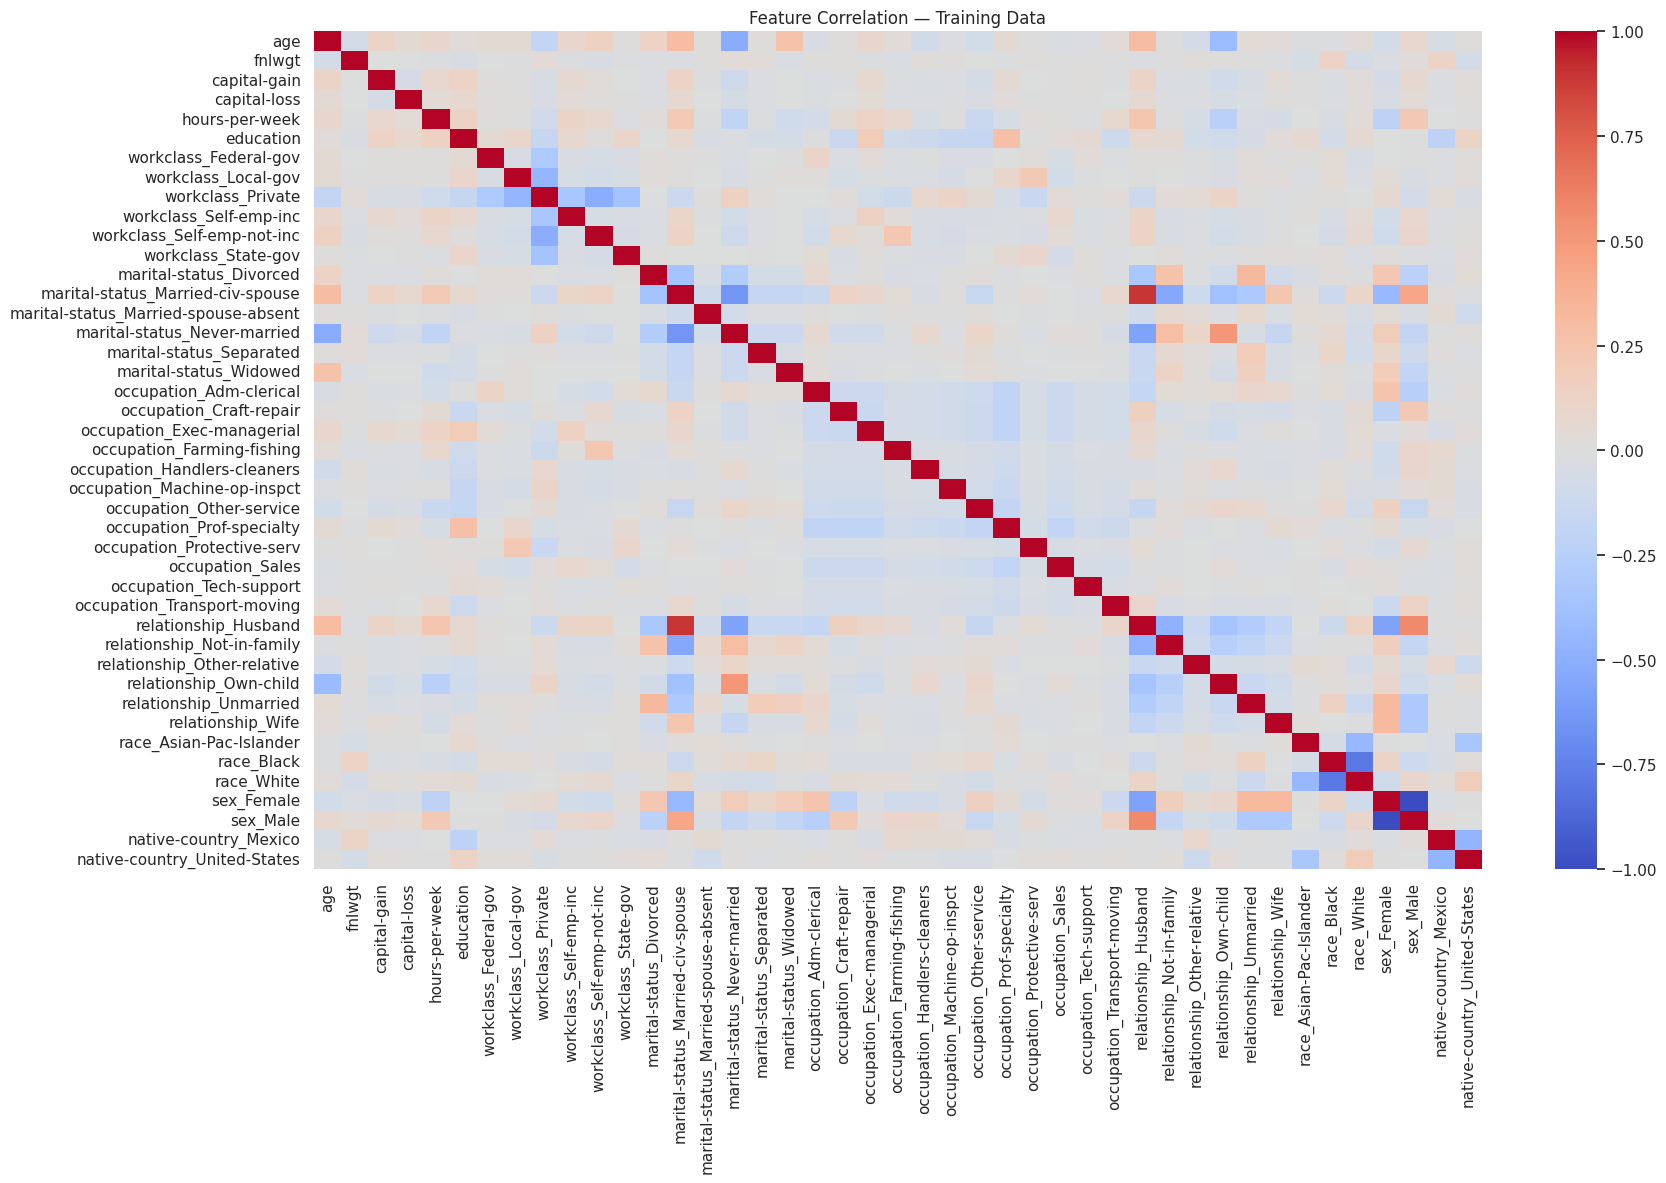

In [39]:
correlation_matrix = X_train_final.corr()

plt.figure(figsize=(18, 12))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0)
plt.title("Feature Correlation — Training Data")
plt.tight_layout()
plt.show()

In [40]:
target_correlation = X_train_final.corrwith(y_train_encoded).sort_values(
    key=lambda values: values.abs(),
    ascending=False
)
display(target_correlation.to_frame("correlation_with_target"))

,correlation_with_target
marital-status_Married-civ-spouse,0.444156
relationship_Husband,0.401988
education,0.331151
marital-status_Never-married,-0.318235
capital-gain,0.286072
relationship_Own-child,-0.224993
hours-per-week,0.218332
age,0.217180
sex_Male,0.213706
sex_Female,-0.213706


 Correlation with the target is calculated using training data only.

## 23. Final preprocessing checks

In [41]:
print("Missing values in final training data:", int(X_train_final.isna().sum().sum()))
print("Missing values in final testing data:", int(X_test_final.isna().sum().sum()))
print("Train and test columns match:", X_train_final.columns.equals(X_test_final.columns))
print("Target train length:", len(y_train_encoded))
print("Target test length:", len(y_test_encoded))
print("Train feature index matches target:", X_train_final.index.equals(y_train_encoded.index))
print("Test feature index matches target:", X_test_final.index.equals(y_test_encoded.index))

Missing values in final training data: 0
Missing values in final testing data: 0
Train and test columns match: True
Target train length: 39050
Target test length: 9763
Train feature index matches target: True
Test feature index matches target: True


##24. Mutual information

In [42]:
mi_scores = mutual_info_classif(
    X_train_final,
    y_train_encoded,
    random_state=42
)

mi_scores = pd.Series(
    mi_scores,
    index=X_train_final.columns
).sort_values(ascending=False)

display(mi_scores)

,0
marital-status_Married-civ-spouse,0.112903
relationship_Husband,0.084837
capital-gain,0.080649
education,0.068244
age,0.065205
marital-status_Never-married,0.063739
relationship_Own-child,0.038704
hours-per-week,0.036010
capital-loss,0.035351
fnlwgt,0.032834


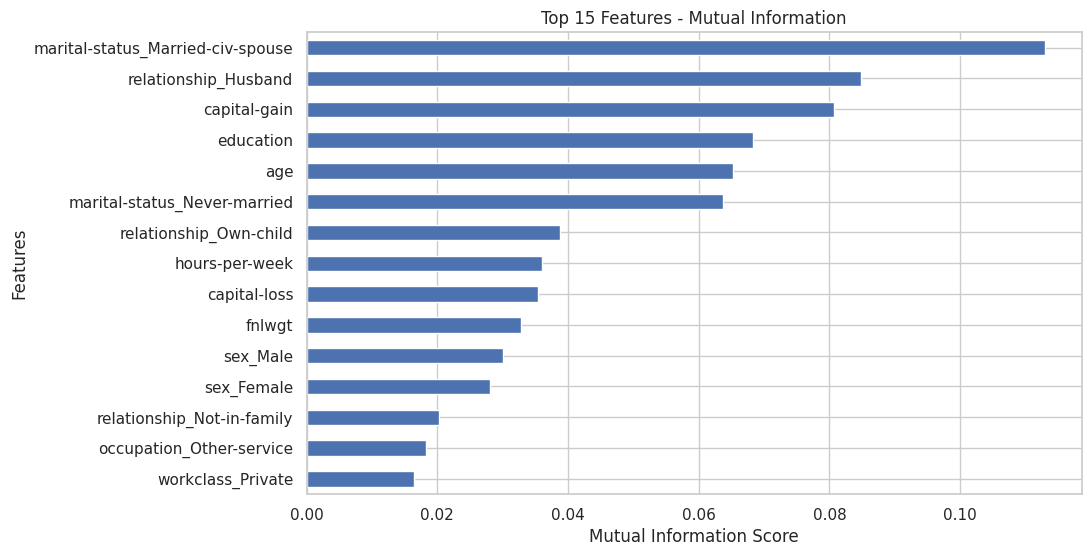

In [43]:
plt.figure(figsize=(10, 6))

mi_scores.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Features - Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.show() #for visualztn

Features with higher scores have stronger statistical relationships with the target.

#### Final Data Preprocessing Summary

This table summarises the problems identified during data inspection, the preprocessing actions performed, and the reasons for selecting those actions.

In [44]:
summary = []

summary.append({
    "Column": "All columns",
    "Problem Found": "Duplicate rows",
    "Action": "Removed duplicates",
    "Reason": "Avoid repeated records"
})

for col in missing_summary.index:
    if missing_summary.loc[col, "missing_count"] > 0:
        if col in numeric_cols:
            action = "Median imputation"
            reason = "Less affected by extreme values"
        else:
            action = "Most frequent imputation"
            reason = "Preserve valid categories"

        summary.append({
            "Column": col,
            "Problem Found": "Missing values",
            "Action": action,
            "Reason": reason
        })

for col in transform_cols:
    summary.append({
        "Column": col,
        "Problem Found": "Right-skewed distribution",
        "Action": "Log1p transformation",
        "Reason": "Reduce skewness"
    })

for col in variance_removed_columns:
    summary.append({
        "Column": col,
        "Problem Found": "Low variance",
        "Action": "Removed using Variance Threshold",
        "Reason": "Reduce low-variance features"
    })

for col in ordinal_cols:
    summary.append({
        "Column": col,
        "Problem Found": "Ordered categorical values",
        "Action": "Ordinal Encoding",
        "Reason": "Preserve category order"
    })

for col in onehot_cols:
    summary.append({
        "Column": col,
        "Problem Found": "Nominal categorical values",
        "Action": "One-Hot Encoding",
        "Reason": "Convert categories into numerical features"
    })

for col in continuous_cols:
    summary.append({
        "Column": col,
        "Problem Found": "Different numerical scales",
        "Action": scaling_choice + " scaling",
        "Reason": "Bring continuous features to comparable scales"
    })

summary.append({
    "Column": target_col,
    "Problem Found": "Categorical target",
    "Action": "Label Encoding",
    "Reason": "Convert target labels into numerical values"
})

summary.append({
    "Column": "Numerical features",
    "Problem Found": "Potential outliers",
    "Action": "Investigated using IQR",
    "Reason": "Avoid removing valid extreme observations"
})

summary_df = pd.DataFrame(summary)

display(summary_df)

,Column,Problem Found,Action,Reason
0,All columns,Duplicate rows,Removed duplicates,Avoid repeated records
1,age,Missing values,Median imputation,Less affected by extreme values
2,workclass,Missing values,Most frequent imputation,Preserve valid categories
3,occupation,Missing values,Most frequent imputation,Preserve valid categories
4,hours-per-week,Missing values,Median imputation,Less affected by extreme values
...,...,...,...,...
65,capital-loss,Different numerical scales,standard scaling,Bring continuous features to comparable scales
66,hours-per-week,Different numerical scales,standard scaling,Bring continuous features to comparable scales
67,education,Different numerical scales,standard scaling,Bring continuous features to comparable scales
68,income,Categorical target,Label Encoding,Convert target labels into numerical values
